Create dynamic, interactive visualizations using Plotly and Dash, integrating filters and drill-down capabilities to enable exploratory data analysis and enhance stakeholder presentations.

In [20]:
import pandas as pd
import numpy as np

In [21]:
np.random.seed(42)

In [22]:
n_samples = 250
n_features = 15

In [23]:
X_raw = np.random.normal(0, 1, size=(n_samples, n_features))
feature_names = [f'feature_{i+1}' for i in range(n_features)]

In [24]:
y_raw = 2.5 * X_raw[:, 0] - 1.8 * X_raw[:, 1] + 3.0 * X_raw[:, 2] + np.random.normal(0, 1, n_samples)

In [25]:
df_features = pd.DataFrame(X_raw, columns=feature_names)
df_features['target'] = y_raw

In [26]:
print("Dataset shape:", df_features.shape)
print("First few rows:")
print(df_features.head())

Dataset shape: (250, 16)
First few rows:
   feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  \
0   0.496714  -0.138264   0.647689   1.523030  -0.234153  -0.234137   
1  -0.562288  -1.012831   0.314247  -0.908024  -1.412304   1.465649   
2  -0.601707   1.852278  -0.013497  -1.057711   0.822545  -1.220844   
3  -0.719844  -0.460639   1.057122   0.343618  -1.763040   0.324084   
4  -0.479174  -0.185659  -1.106335  -1.196207   0.812526   1.356240   

   feature_7  feature_8  feature_9  feature_10  feature_11  feature_12  \
0   1.579213   0.767435  -0.469474    0.542560   -0.463418   -0.465730   
1  -0.225776   0.067528  -1.424748   -0.544383    0.110923   -1.150994   
2   0.208864  -1.959670  -1.328186    0.196861    0.738467    0.171368   
3  -0.385082  -0.676922   0.611676    1.031000    0.931280   -0.839218   
4  -0.072010   1.003533   0.361636   -0.645120    0.361396    1.538037   

   feature_13  feature_14  feature_15    target  
0    0.241962   -1.913280   -1.724918

In [28]:
from sklearn.preprocessing import PolynomialFeatures

In [29]:
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)

In [30]:
primary_cols = ['feature_1', 'feature_2', 'feature_3']
interactions = poly.fit_transform(df_features[primary_cols])
interaction_cols = poly.get_feature_names_out(primary_cols)

In [31]:
df_interactions = pd.DataFrame(interactions, columns=interaction_cols)

In [32]:
print(df_interactions.head())

   feature_1  feature_2  feature_3  feature_1 feature_2  feature_1 feature_3  \
0   0.496714  -0.138264   0.647689            -0.068678             0.321716   
1  -0.562288  -1.012831   0.314247             0.569502            -0.176697   
2  -0.601707   1.852278  -0.013497            -1.114528             0.008121   
3  -0.719844  -0.460639   1.057122             0.331588            -0.760963   
4  -0.479174  -0.185659  -1.106335             0.088963             0.530127   

   feature_2 feature_3  
0            -0.089552  
1            -0.318279  
2            -0.025001  
3            -0.486951  
4             0.205401  


In [33]:
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.linear_model import LinearRegression

In [34]:
X = df_features[feature_names]
y = df_features['target']

In [35]:
selector_kbest = SelectKBest(score_func=f_regression, k=8)
X_kbest = selector_kbest.fit_transform(X, y)
selected_kbest_features = X.columns[selector_kbest.get_support()].tolist()

In [36]:
print("Stage 1 - Top 8 Features selected via SelectKBest:")
print(selected_kbest_features)

Stage 1 - Top 8 Features selected via SelectKBest:
['feature_1', 'feature_2', 'feature_3', 'feature_5', 'feature_9', 'feature_10', 'feature_11', 'feature_13']


In [37]:
estimator = LinearRegression()
selector_rfe = RFE(estimator=estimator, n_features_to_select=3, step=1)
selector_rfe.fit(X[selected_kbest_features], y)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LinearRegression()
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",3
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,LinearRegression,LinearRegression()
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['feature_1','feature_2','feature_3',...,'feature_10','feature_11', 'feature_13']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(3)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,8
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](8,)","[1,1,1,...,3,5,6]"


In [38]:
final_features = np.array(selected_kbest_features)[selector_rfe.support_].tolist()

In [39]:
print(final_features)

['feature_1', 'feature_2', 'feature_3']


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [42]:
full_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kbest', SelectKBest(score_func=f_regression, k=5)),
    ('model', LinearRegression())
])

In [43]:
full_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('kbest', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['feature_1','feature_2','feature_3',...,'feature_13','feature_14', 'feature_15']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [44]:
y_pred = full_pipeline.predict(X_test)

In [45]:
print("--- Pipeline Performance Summary ---")
print("Test R2 Score:", round(r2_score(y_test, y_pred), 4))
print("Test Root Mean Squared Error (RMSE):", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

--- Pipeline Performance Summary ---
Test R2 Score: 0.964
Test Root Mean Squared Error (RMSE): 0.8339


In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

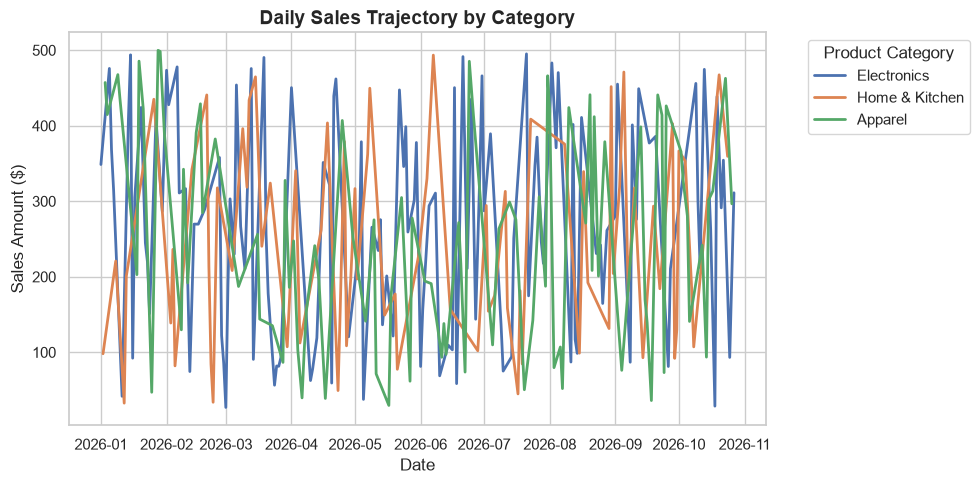

In [47]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Plot daily sales trajectory
sns.lineplot(
    data=df_sales, 
    x='date', 
    y='sales', 
    hue='category', 
    linewidth=2
)

plt.title("Daily Sales Trajectory by Category", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Sales Amount ($)", fontsize=12)
plt.legend(title="Product Category", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()